# Land Price Prediction – BhoomiVista Realty

**Goal:** Predict the selling price of a land plot (in ₹ lakhs) from its details, like city, size, road width and nearby facilities.

**Data file:** `Land_Sales_History.xlsx` (keep it in the same folder as this notebook)

**Steps in this notebook:**
1. Load the data
2. Look at the data
3. Clean the data (remove duplicates, fix text, fill missing values with mean / median / mode)
4. Explore the data (EDA) with simple tables and charts
5. Prepare the data for machine learning
6. Train 3 machine learning models
7. Check each model with **mean squared error (MSE)** and pick the best one
8. Use the best model to predict the price of a new plot

## Step 1: Import the libraries

- **pandas** – to read and work with tables
- **numpy** – for simple number work
- **matplotlib** – to draw charts
- **sklearn** – for machine learning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

## Step 2: Load the data

We read the Excel file that the company gave us. Each row is one plot that the company sold in the past, with its final selling price.

In [2]:
df = pd.read_excel("Land_Sales_History.xlsx")
df.head()

,Plot_ID,City,Area_Type,Plot_Size_SqFt,Road_Width_Ft,Distance_To_City_Center_Km,Distance_To_Highway_Km,Facing,Corner_Plot,Near_School,Near_Hospital,Gated_Society,Year_Sold,Price_Lakhs
0,P21277,Dehradun,Rural,2400.0,20.0,27.0,8.2,South,No,No,No,Yes,2022,30.46
1,P21689,Indore,Urban,600.0,40.0,8.8,19.0,NaN,Yes,Yes,Yes,Yes,2022,30.22
2,P20661,DEHRADUN,Rural,2000.0,30.0,39.2,19.7,East,Yes,No,No,No,2025,22.68
3,P21540,Jaipur,Semi-Urban,1200.0,20.0,10.3,16.1,West,No,No,Yes,No,2024,29.19
4,P20502,Noida,Urban,1000.0,30.0,4.7,7.1,West,No,No,No,No,2022,84.23


## Step 3: Look at the data

Before changing anything, we check:
- how many rows and columns there are
- the column names and their type (number or text)

In [3]:
print("Rows and columns:", df.shape)

Rows and columns: (1828, 14)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1828 entries, 0 to 1827
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Plot_ID                     1828 non-null   str    
 1   City                        1828 non-null   str    
 2   Area_Type                   1828 non-null   str    
 3   Plot_Size_SqFt              1792 non-null   float64
 4   Road_Width_Ft               1754 non-null   float64
 5   Distance_To_City_Center_Km  1828 non-null   float64
 6   Distance_To_Highway_Km      1738 non-null   float64
 7   Facing                      1774 non-null   str    
 8   Corner_Plot                 1828 non-null   str    
 9   Near_School                 1828 non-null   str    
 10  Near_Hospital               1755 non-null   str    
 11  Gated_Society               1828 non-null   str    
 12  Year_Sold                   1828 non-null   int64  
 13  Price_Lakhs                 1828 non-null   

## Step 4: Clean the data

We will fix three problems:
1. **Duplicate rows** – the same sale entered two times
2. **Messy text** – the same city written in different ways (like `noida`, `NOIDA`, ` Noida`)
3. **Missing values** – empty cells

### 4.1 Remove duplicate rows

In [5]:
print("Duplicate rows found:", df.duplicated().sum())

Duplicate rows found: 28


In [6]:
df = df.drop_duplicates()
print("Rows after removing duplicates:", df.shape[0])

Rows after removing duplicates: 1800


### 4.2 Fix messy text

In [7]:
print("City values before fixing:")
print(df["City"].unique())
print()
print("Area type values before fixing:")
print(df["Area_Type"].unique())

City values before fixing:
<StringArray>
[ 'Dehradun',    'Indore',  'DEHRADUN',    'Jaipur',     'Noida',  'Gurugram',
   'Lucknow',    'jaipur',    'JAIPUR',     'noida',    'indore',  'gurugram',
   ' Jaipur', ' Dehradun',   ' Indore',  ' Lucknow',  'GURUGRAM',   'lucknow',
    'INDORE',  'dehradun',     'NOIDA', ' Gurugram',   'LUCKNOW',    ' Noida']
Length: 24, dtype: str

Area type values before fixing:
<StringArray>
['Rural', 'Urban', 'Semi-Urban', 'semi-urban', 'urban', 'rural']
Length: 6, dtype: str


- `str.strip()` removes extra spaces at the start and end
- `str.title()` makes the first letter of each word capital and the rest small

In [8]:
df["City"] = df["City"].str.strip().str.title()
df["Area_Type"] = df["Area_Type"].str.strip().str.title()

print("City values after fixing:")
print(df["City"].unique())
print()
print("Area type values after fixing:")
print(df["Area_Type"].unique())

City values after fixing:
<StringArray>
['Dehradun', 'Indore', 'Jaipur', 'Noida', 'Gurugram', 'Lucknow']
Length: 6, dtype: str

Area type values after fixing:
<StringArray>
['Rural', 'Urban', 'Semi-Urban']
Length: 3, dtype: str


### 4.3 Fill missing values

First we count the empty cells in each column.

In [9]:
df.isna().sum()

Plot_ID                        0
City                           0
Area_Type                      0
Plot_Size_SqFt                36
Road_Width_Ft                 72
Distance_To_City_Center_Km     0
Distance_To_Highway_Km        90
Facing                        54
Corner_Plot                    0
Near_School                    0
Near_Hospital                 72
Gated_Society                  0
Year_Sold                      0
Price_Lakhs                    0
dtype: int64

We fill empty cells with **only three simple methods**:

| Method | What it means | When we use it |
|---|---|---|
| **Mean** | The average value | For number columns where values are spread evenly |
| **Median** | The middle value when all values are put in order | For number columns where a few very big values can pull the average up |
| **Mode** | The value that appears the most | For text columns, Yes/No columns, and number columns that have only a few fixed options |

**Plot_Size_SqFt → Median.** Most plots are small or medium, but a few are very big (4,000–5,000 sq ft). These big plots pull the average up, so the middle value is a fairer guess.

In [10]:
print("Mean plot size  :", round(df["Plot_Size_SqFt"].mean()))
print("Median plot size:", df["Plot_Size_SqFt"].median())

size_median = df["Plot_Size_SqFt"].median()
df["Plot_Size_SqFt"] = df["Plot_Size_SqFt"].fillna(size_median)

Mean plot size  : 1748
Median plot size: 1500.0


**Distance_To_Highway_Km → Mean.** Distances are spread evenly from very near to far, so the average distance is a fair guess. We round it to 1 decimal place like the rest of the column.

In [11]:
highway_mean = round(df["Distance_To_Highway_Km"].mean(), 1)
print("Mean distance to highway:", highway_mean, "km")

df["Distance_To_Highway_Km"] = df["Distance_To_Highway_Km"].fillna(highway_mean)

Mean distance to highway: 10.2 km


**Road_Width_Ft → Mode.** Roads come in only a few fixed widths (12, 20, 30, 40, 60 ft). A road of 26.4 ft does not exist, so we use the most common width.

**Facing, Near_Hospital → Mode.** These are text columns, so we use the most common value.

In [12]:
road_mode = df["Road_Width_Ft"].mode()[0]
facing_mode = df["Facing"].mode()[0]
hospital_mode = df["Near_Hospital"].mode()[0]

print("Most common road width :", road_mode)
print("Most common facing     :", facing_mode)
print("Most common hospital   :", hospital_mode)

df["Road_Width_Ft"] = df["Road_Width_Ft"].fillna(road_mode)
df["Facing"] = df["Facing"].fillna(facing_mode)
df["Near_Hospital"] = df["Near_Hospital"].fillna(hospital_mode)

Most common road width : 20.0
Most common facing     : East
Most common hospital   : No


Now we check again. Every column should show **0** missing values.

In [13]:
df.isna().sum()

Plot_ID                       0
City                          0
Area_Type                     0
Plot_Size_SqFt                0
Road_Width_Ft                 0
Distance_To_City_Center_Km    0
Distance_To_Highway_Km        0
Facing                        0
Corner_Plot                   0
Near_School                   0
Near_Hospital                 0
Gated_Society                 0
Year_Sold                     0
Price_Lakhs                   0
dtype: int64

In [14]:
print("Clean data shape:", df.shape)
df.head()

Clean data shape: (1800, 14)


,Plot_ID,City,Area_Type,Plot_Size_SqFt,Road_Width_Ft,Distance_To_City_Center_Km,Distance_To_Highway_Km,Facing,Corner_Plot,Near_School,Near_Hospital,Gated_Society,Year_Sold,Price_Lakhs
0,P21277,Dehradun,Rural,2400.0,20.0,27.0,8.2,South,No,No,No,Yes,2022,30.46
1,P21689,Indore,Urban,600.0,40.0,8.8,19.0,East,Yes,Yes,Yes,Yes,2022,30.22
2,P20661,Dehradun,Rural,2000.0,30.0,39.2,19.7,East,Yes,No,No,No,2025,22.68
3,P21540,Jaipur,Semi-Urban,1200.0,20.0,10.3,16.1,West,No,No,Yes,No,2024,29.19
4,P20502,Noida,Urban,1000.0,30.0,4.7,7.1,West,No,No,No,No,2022,84.23


## Step 5: Explore the data (EDA)

EDA means **looking at the data to understand it** before building a model.
We ask simple business questions and answer them with tables and charts.

### 5.1 Summary of number columns

In [15]:
df.describe().round(1)

,Plot_Size_SqFt,Road_Width_Ft,Distance_To_City_Center_Km,Distance_To_Highway_Km,Year_Sold,Price_Lakhs
count,1800.0,1800.0,1800.0,1800.0,1800.0,1800.0
mean,1743.2,27.0,15.2,10.2,2022.0,80.6
std,949.6,12.9,10.3,5.5,2.0,76.2
min,600.0,12.0,1.0,0.2,2019.0,3.8
25%,1000.0,20.0,7.0,5.5,2020.0,30.0
50%,1500.0,20.0,12.9,10.2,2022.0,55.7
75%,2000.0,30.0,21.2,14.6,2024.0,104.3
max,5000.0,60.0,39.9,20.0,2025.0,658.4


### 5.2 Which city has the costliest plots?

In [16]:
price_by_city = df.groupby("City")["Price_Lakhs"].mean().round(1).sort_values(ascending=False)
price_by_city

City
Gurugram    130.3
Noida       101.6
Dehradun     63.5
Jaipur       58.8
Lucknow      54.7
Indore       51.1
Name: Price_Lakhs, dtype: float64

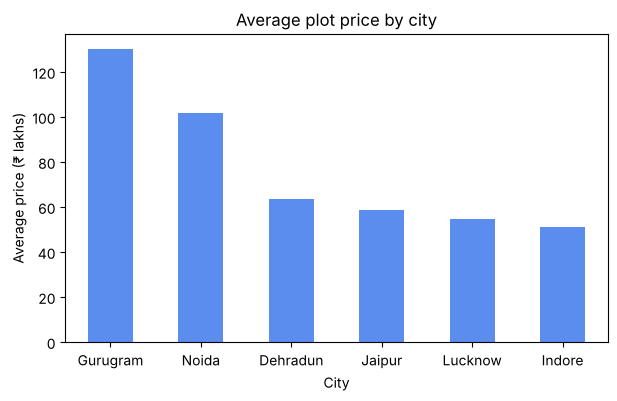

In [17]:
price_by_city.plot(kind="bar", color="#5B8DEF", figsize=(7, 4))
plt.title("Average plot price by city")
plt.xlabel("City")
plt.ylabel("Average price (₹ lakhs)")
plt.xticks(rotation=0)
plt.show()

### 5.3 Urban vs Semi-Urban vs Rural

In [18]:
price_by_area = df.groupby("Area_Type")["Price_Lakhs"].mean().round(1).sort_values(ascending=False)
price_by_area

Area_Type
Urban         128.6
Semi-Urban     68.7
Rural          27.3
Name: Price_Lakhs, dtype: float64

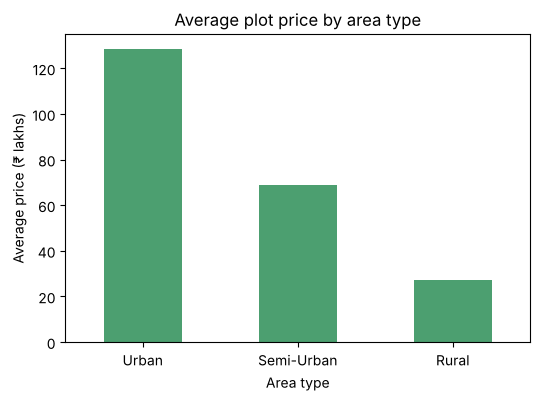

In [19]:
price_by_area.plot(kind="bar", color="#4C9F70", figsize=(6, 4))
plt.title("Average plot price by area type")
plt.xlabel("Area type")
plt.ylabel("Average price (₹ lakhs)")
plt.xticks(rotation=0)
plt.show()

### 5.4 Do bigger plots sell for more?

Each dot is one plot. If the dots go up from left to right, bigger plots cost more.

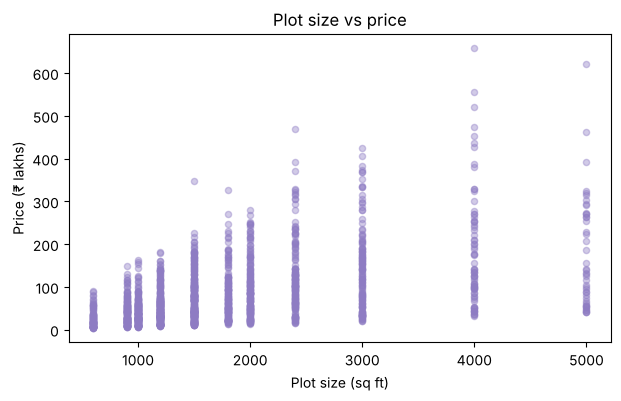

In [20]:
df.plot(kind="scatter", x="Plot_Size_SqFt", y="Price_Lakhs", alpha=0.4, color="#8E7CC3", figsize=(7, 4))
plt.title("Plot size vs price")
plt.xlabel("Plot size (sq ft)")
plt.ylabel("Price (₹ lakhs)")
plt.show()

### 5.5 Does distance from the city centre matter?

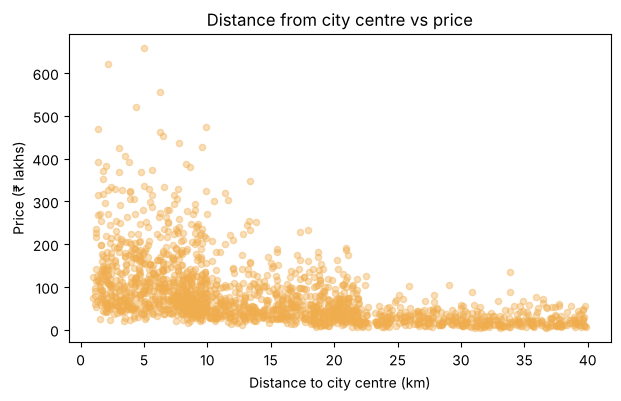

In [21]:
df.plot(kind="scatter", x="Distance_To_City_Center_Km", y="Price_Lakhs", alpha=0.4, color="#F0AD4E", figsize=(7, 4))
plt.title("Distance from city centre vs price")
plt.xlabel("Distance to city centre (km)")
plt.ylabel("Price (₹ lakhs)")
plt.show()

### 5.6 How have prices changed over the years?

In [22]:
price_by_year = df.groupby("Year_Sold")["Price_Lakhs"].mean().round(1)
price_by_year

Year_Sold
2019    70.5
2020    67.5
2021    76.6
2022    80.5
2023    80.5
2024    90.9
2025    96.1
Name: Price_Lakhs, dtype: float64

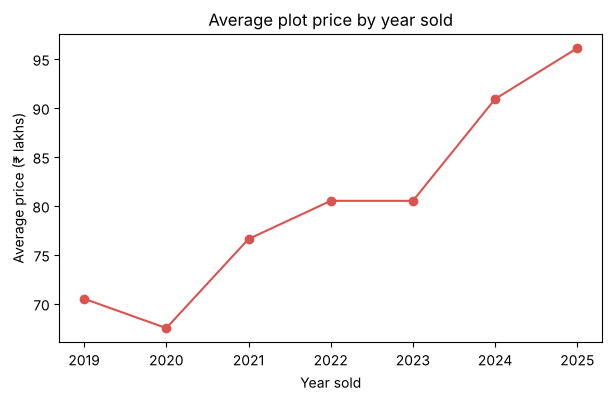

In [23]:
price_by_year.plot(kind="line", marker="o", color="#D9534F", figsize=(7, 4))
plt.title("Average plot price by year sold")
plt.xlabel("Year sold")
plt.ylabel("Average price (₹ lakhs)")
plt.show()

### 5.7 Do extra features increase the price?

We compare the average price of plots **with** and **without** each feature.

In [24]:
corner = df.groupby("Corner_Plot")["Price_Lakhs"].mean()
gated = df.groupby("Gated_Society")["Price_Lakhs"].mean()
school = df.groupby("Near_School")["Price_Lakhs"].mean()
hospital = df.groupby("Near_Hospital")["Price_Lakhs"].mean()

feature_table = pd.DataFrame({
    "Corner_Plot": corner,
    "Gated_Society": gated,
    "Near_School": school,
    "Near_Hospital": hospital
}).T.round(1)

feature_table = feature_table[["Yes", "No"]]
feature_table

,Yes,No
Corner_Plot,88.4,79.0
Gated_Society,88.2,77.5
Near_School,99.3,60.6
Near_Hospital,104.7,62.5


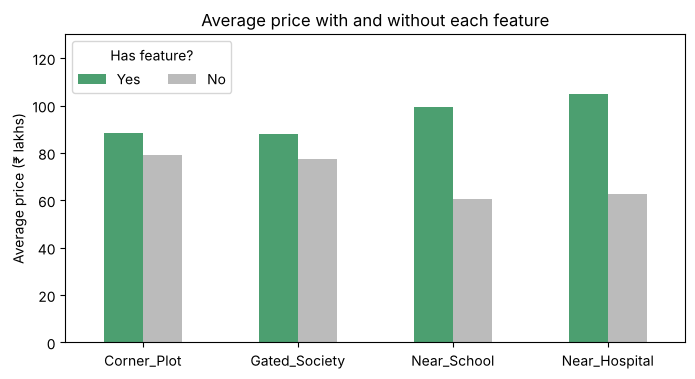

In [25]:
feature_table.plot(kind="bar", color=["#4C9F70", "#BBBBBB"], figsize=(8, 4))
plt.title("Average price with and without each feature")
plt.ylim(0, 130)
plt.legend(title="Has feature?", loc="upper left", ncol=2)
plt.ylabel("Average price (₹ lakhs)")
plt.xticks(rotation=0)
plt.show()

### 5.8 Does road width matter?

In [26]:
df.groupby("Road_Width_Ft")["Price_Lakhs"].mean().round(1)

Road_Width_Ft
12.0    76.9
20.0    79.6
30.0    82.0
40.0    82.2
60.0    86.3
Name: Price_Lakhs, dtype: float64

### What we learned from EDA

1. **City matters a lot.** Gurugram (₹130.3 lakhs) and Noida (₹101.6 lakhs) have the costliest plots on average. Indore (₹51.1 lakhs) is the cheapest.
2. **Area type matters a lot.** An average Urban plot sells for ₹128.6 lakhs, Semi-Urban for ₹68.7 lakhs and Rural for only ₹27.3 lakhs.
3. **Bigger plots sell for more.** In the scatter chart, the dots go up as the plot size grows.
4. **Plots far from the city centre are cheaper.** The dots go down as the distance grows.
5. **Prices are rising.** The average price went from ₹70.5 lakhs in 2019 to ₹96.1 lakhs in 2025.
6. **Corner plots and gated societies sell for more** (about ₹9–11 lakhs more on average).
7. **Plots near a school or hospital show a very big difference.** But be careful: most of these plots are in urban areas, which are costly anyway. So this gap is not only because of the school or hospital.
8. **Wider roads give a slightly higher price** (₹76.9 lakhs for 12 ft roads, ₹86.3 lakhs for 60 ft roads).

Point 7 shows why we need machine learning: many things affect the price **at the same time**. A model looks at all the columns together, which is hard for a person to do by looking at one chart at a time.

## Step 6: Prepare the data for machine learning

A machine learning model understands **only numbers**. So we:
1. Remove **Plot_ID** – it is just a name tag and does not affect the price
2. Turn Yes/No columns into 1/0
3. Turn other text columns into number columns using `pd.get_dummies()`

In [27]:
data = df.drop(columns=["Plot_ID"])

yes_no_cols = ["Corner_Plot", "Near_School", "Near_Hospital", "Gated_Society"]
for col in yes_no_cols:
    data[col] = np.where(data[col] == "Yes", 1, 0)

data[yes_no_cols].head()

,Corner_Plot,Near_School,Near_Hospital,Gated_Society
0,0,0,0,1
1,1,1,1,1
2,1,0,0,0
3,0,0,1,0
4,0,0,0,0


**What does `get_dummies` do?**

It turns one text column into several 0/1 columns. For example, the `Area_Type` column becomes:

| Area_Type_Rural | Area_Type_Semi-Urban | Area_Type_Urban |
|---|---|---|
| 0 | 0 | 1 |
| 1 | 0 | 0 |

So an Urban plot gets 1 in the Urban column and 0 in the others.

In [28]:
text_cols = ["City", "Area_Type", "Facing"]
data = pd.get_dummies(data, columns=text_cols, dtype=int)
data.head()

,Plot_Size_SqFt,Road_Width_Ft,Distance_To_City_Center_Km,Distance_To_Highway_Km,Corner_Plot,Near_School,Near_Hospital,Gated_Society,Year_Sold,Price_Lakhs,...,City_Jaipur,City_Lucknow,City_Noida,Area_Type_Rural,Area_Type_Semi-Urban,Area_Type_Urban,Facing_East,Facing_North,Facing_South,Facing_West
0,2400.0,20.0,27.0,8.2,0,0,0,1,2022,30.46,...,0,0,0,1,0,0,0,0,1,0
1,600.0,40.0,8.8,19.0,1,1,1,1,2022,30.22,...,0,0,0,0,0,1,1,0,0,0
2,2000.0,30.0,39.2,19.7,1,0,0,0,2025,22.68,...,0,0,0,1,0,0,1,0,0,0
3,1200.0,20.0,10.3,16.1,0,0,1,0,2024,29.19,...,1,0,0,0,1,0,0,0,0,1
4,1000.0,30.0,4.7,7.1,0,0,0,0,2022,84.23,...,0,0,1,0,0,1,0,0,0,1


Now we split the table into two parts:
- **X** = the input columns (everything we know about the plot)
- **y** = the answer column (Price_Lakhs: what price the plot sold for)

In [29]:
X = data.drop(columns=["Price_Lakhs"])
y = data["Price_Lakhs"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1800, 22)
y shape: (1800,)


### Train and test split

We keep **80%** of the plots to **teach** the model (train data) and hide **20%** to **test** the model later (test data).
This is like a student who practises on some questions and then takes an exam on new questions.

`random_state=42` makes sure we get the same split every time we run the notebook.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train rows:", X_train.shape[0])
print("Test rows :", X_test.shape[0])

Train rows: 1440
Test rows : 360


## Step 7: Train the models and check the error

We try **3 simple models** and compare them:

1. **Linear Regression** – draws the best straight-line relationship between the inputs and the price
2. **Decision Tree** – asks a chain of yes/no questions, like a flowchart, and gives a price at the end
3. **Random Forest** – builds many decision trees and takes the average of their answers

**Mean Squared Error (MSE)** tells us how far the predicted prices are from the real prices.
- For every test plot, we find the gap between the real price and the predicted price
- Each gap is multiplied by itself (so a minus gap also becomes a plus number)
- Then we take the average of all these numbers

**Lower MSE = better model.** An MSE of 0 would mean every prediction is perfect.

### Model 1: Linear Regression

In [31]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

lin_pred = lin_model.predict(X_test)
lin_mse = mean_squared_error(y_test, lin_pred)
print("Linear Regression MSE:", round(lin_mse, 1))

Linear Regression MSE: 1122.4


### Model 2: Decision Tree

In [32]:
tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
tree_mse = mean_squared_error(y_test, tree_pred)
print("Decision Tree MSE:", round(tree_mse, 1))

Decision Tree MSE: 818.3


### Model 3: Random Forest

In [33]:
forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)
forest_mse = mean_squared_error(y_test, forest_pred)
print("Random Forest MSE:", round(forest_mse, 1))

Random Forest MSE: 420.0


### Compare the three models

In [34]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MSE": [lin_mse, tree_mse, forest_mse]
})
results["MSE"] = results["MSE"].round(1)
results = results.sort_values("MSE")
results

,Model,MSE
2,Random Forest,420.0
1,Decision Tree,818.3
0,Linear Regression,1122.4


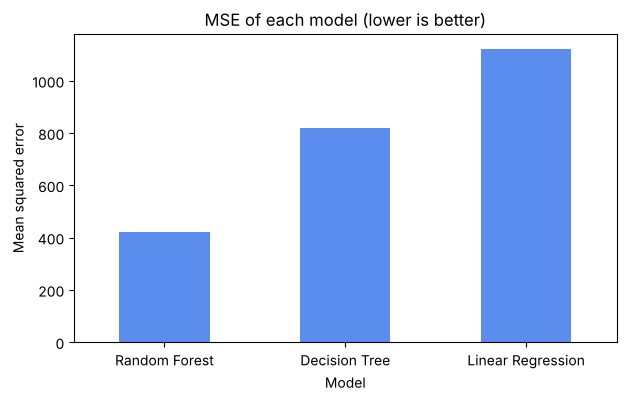

In [35]:
results.plot(x="Model", y="MSE", kind="bar", legend=False, color="#5B8DEF", figsize=(7, 4))
plt.title("MSE of each model (lower is better)")
plt.ylabel("Mean squared error")
plt.xticks(rotation=0)
plt.show()

### Which model is the best?

| Model | MSE (lower is better) |
|---|---|
| Random Forest | **420.0** |
| Decision Tree | 818.3 |
| Linear Regression | 1122.4 |

**Random Forest is the best model.** Its error is much lower than the other two models.

**Why is Linear Regression the weakest?** It tries to explain the price with straight-line relationships. But land price does not work like that. For example, 100 extra sq ft adds much more money in urban Gurugram than in a rural plot in Indore. Tree models can learn these "it depends" rules.

**Why is Random Forest better than one Decision Tree?** One tree can learn the training data too closely. Random Forest builds many trees and takes the average of their answers, so its predictions are steadier.

We will use **Random Forest** for the next steps.

## Step 8: Check some predictions

Let us look at 10 test plots: the real selling price vs the price the model predicted.

In [36]:
check = pd.DataFrame({
    "City": df.loc[X_test.index, "City"].values[:10],
    "Plot_Size_SqFt": X_test["Plot_Size_SqFt"].values[:10],
    "Actual Price (lakhs)": y_test.values[:10],
    "Predicted Price (lakhs)": forest_pred[:10].round(2)
})
check["Difference (lakhs)"] = (check["Actual Price (lakhs)"] - check["Predicted Price (lakhs)"]).round(2)
check

,City,Plot_Size_SqFt,Actual Price (lakhs),Predicted Price (lakhs),Difference (lakhs)
0,Lucknow,900.0,52.89,46.07,6.82
1,Dehradun,1000.0,59.20,55.31,3.89
2,Indore,2000.0,133.03,129.87,3.16
3,Jaipur,2400.0,103.46,102.87,0.59
4,Gurugram,900.0,75.32,86.20,-10.88
5,Gurugram,1500.0,348.03,94.83,253.20
6,Lucknow,5000.0,263.29,228.07,35.22
7,Indore,1200.0,13.84,13.14,0.70
8,Lucknow,1500.0,82.39,87.96,-5.57
9,Jaipur,900.0,40.41,44.37,-3.96


Most predictions are close to the real price, within a few lakhs.

**One big miss:** the Gurugram plot in row 5 sold for ₹348 lakhs, but the model predicted only about ₹95 lakhs. This plot's size was **missing** in the company's data, and we filled it with the median size (1,500 sq ft). The real plot was most likely much bigger, so the model got the wrong size and gave a wrong price.

**Lesson:** Filling missing values lets us keep the row, but a filled value is only a guess. The company should record the plot size for every sale.

## Step 9: Predict the price of a new plot

This is how the sales team will use the model. We give the details of one plot and the model gives a fair price.

We must turn the new plot's text values into 0/1 columns in the same way, and make sure the columns are in the same order as X. `reindex` does this and fills any missing column with 0.

In [37]:
new_plot = pd.DataFrame({
    "City": ["Jaipur"],
    "Area_Type": ["Semi-Urban"],
    "Plot_Size_SqFt": [1500],
    "Road_Width_Ft": [30],
    "Distance_To_City_Center_Km": [12],
    "Distance_To_Highway_Km": [3],
    "Facing": ["East"],
    "Corner_Plot": ["Yes"],
    "Near_School": ["Yes"],
    "Near_Hospital": ["No"],
    "Gated_Society": ["Yes"],
    "Year_Sold": [2025]
})

for col in yes_no_cols:
    new_plot[col] = np.where(new_plot[col] == "Yes", 1, 0)

new_data = pd.get_dummies(new_plot, columns=text_cols, dtype=int)
new_data = new_data.reindex(columns=X.columns, fill_value=0)

price = forest_model.predict(new_data)[0]
print("Predicted price of this plot: ₹", round(price, 2), "lakhs")

Predicted price of this plot: ₹ 51.04 lakhs


## Conclusion

- We cleaned the company's old sales data: removed 28 duplicate rows, fixed messy city and area type names, and filled missing values using only mean, median and mode.
- EDA showed that **city, area type, plot size, distance from the city centre and the year of sale** have the biggest effect on price. Corner plots, gated societies and wider roads add some extra value.
- We trained 3 models. **Random Forest gave the lowest mean squared error (420.0)**, so it is the best model.

**How the company can use this:** When a new plot comes in, the sales team enters its details and the model gives a fair price in seconds. This helps the team avoid pricing a plot too high (it will not sell) or too low (the company loses money). The model should be trained again with new sales data every few months, because land prices keep changing.